# Project summary: final selection, replication over instances, one table
Final iteration of the encoder experiments on GA trajectories for the TSP (STN with clustered locations, permutation space vs embedding). Everything below was fixed and committed before its results were computed: the dev set, the k values, the variants, the selection rule and the replication instances (`contrastive_trajectory_config.yaml`: `dev_set_config`, `selection_config`, `replication_config`; `dl_permutations.project_summary`: `FINAL_VARIANTS`, `FINAL_SELECTIONS`).

**Criterion** of a trained encoder: the mean of four gains over its own random init (same architecture and seed), each averaged over k = 20 and 50 where it depends on k: the soft agreement (per-tour Spearman of the distances to the k centers; partly the training target itself, since every objective orders triplets by edge distance), the funnel (`-|best_strength - best_strength of the permutation space|`), `end_equal` and the generation probe (pooled out-of-fold R^2).

**Selection rule** (on the dev set: 100 new GA runs on instance 1, seeds 1200-1299, never used for training or testing): the highest mean criterion over 3 seeds wins unless another variant is tied with it, i.e. the difference is below 2 bootstrap standard errors (1000 resamples of the dev runs, the same draws for every variant); among tied variants the simpler one (order of `FINAL_SELECTIONS`). The test runs only report.

**Default variant**: `incidence_mlp`, edge-distance triplets of the elites, w = 0, 200 epochs, last epoch. In the previous iteration the rule picked w = 1 on the 20 validation runs, which the test runs did not confirm (validation too small, tie rule on the seed spread only); the local term is an option for local accuracy. Populations + local term is dropped (reported as history).

**Replication**: 5 new instances (TSP seeds 101-105), `incidence_mlp` w = 0 trained on the elites and on the populations of each instance (1 seed), evaluated on the test runs of the instance; the instance is the unit of replication (mean, sd and SE over instances).

**Limitations**: no transfer between instances (training per instance is the standard); the LSTM is not fully converged at 200 epochs; v1 is history only (GA before the off-by-one fix, best-validation checkpoints).

**Reference** (added after the results, at the reviewer's decision): classical MDS(64) of the edge distances, a compression without learning, is the reference of the project (upper bound without learning) and the anchor row of the project table; see the baselines and the conclusions at the end.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == 'notebooks':
    os.chdir("..")

In [2]:
import csv
import os

import numpy as np
import torch
from dl_permutations import project_summary as P
from dl_permutations import stn_clusters as S

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sets = P.final_sets()
models = P.final_models(device)
results = {}
for set_name, d in sets.items():
    pieces, summary = P.evaluate_set(models, d, device)
    results[set_name] = (pieces, summary, P.bootstrap_weights(len(np.unique(d["run_id"]))))
    print(f"{set_name}: {len(d['perm'])} elites, {len(np.unique(d['run_id']))} runs")

validation: 392 elites, 20 runs


dev: 1898 elites, 100 runs


test: 1850 elites, 100 runs


## Final selection on the dev set
Per selection: the mean criterion over seeds, its seed sd and bootstrap SE, the difference to the top with its bootstrap SE, whether it is tied, and the mean gain per component. The same rule on the validation and test runs is shown for information only.

In [3]:
def fmt(rows):
    return [{k: (f"{v:+.3f}" if isinstance(v, float) else v) for k, v in r.items()} for r in rows]

choices = {}
for selection, candidates in P.FINAL_SELECTIONS.items():
    for set_name in ("dev", "validation", "test"):
        pieces, _, W = results[set_name]
        choice, rows = P.select(pieces, candidates, W)
        if set_name == "dev":
            choices[selection] = choice
        print(f"===== {selection} | {set_name}{'' if set_name == 'dev' else ' (information only)'} -> {choice}")
        print(S.format_table(fmt(rows), list(rows[0])), end="\n\n")
print("choices on the dev set:", choices)

===== architecture (edge objective, w = 0) | dev -> lstm
      variant criterion seed sd boot SE diff to top SE of diff tied with top  Δsoft Δfunnel Δend_equal Δgen_r2
incidence_mlp    +0.191  +0.028  +0.014      +0.111     +0.020         False +0.344  +0.120     +0.172  +0.129
edge_deepsets    +0.109  +0.017  +0.013      +0.192     +0.018         False +0.332  -0.038     +0.125  +0.019
         lstm    +0.302  +0.018  +0.020      +0.000     +0.000          True +0.627  -0.072     +0.210  +0.442

===== architecture (edge objective, w = 0) | validation (information only) -> lstm
      variant criterion seed sd boot SE diff to top SE of diff tied with top  Δsoft Δfunnel Δend_equal Δgen_r2
incidence_mlp    +0.226  +0.038  +0.029      +0.144     +0.038         False +0.311  +0.067     +0.183  +0.342
edge_deepsets    +0.205  +0.049  +0.030      +0.164     +0.044         False +0.384  +0.067     +0.208  +0.163
         lstm    +0.370  +0.022  +0.038      +0.000     +0.000          True +0.64

===== architecture (edge objective, w = 0) | test (information only) -> lstm
      variant criterion seed sd boot SE diff to top SE of diff tied with top  Δsoft Δfunnel Δend_equal Δgen_r2
incidence_mlp    +0.148  +0.033  +0.013      +0.245     +0.018         False +0.316  -0.000     +0.153  +0.123
edge_deepsets    +0.148  +0.010  +0.014      +0.245     +0.016         False +0.308  +0.113     +0.138  +0.033
         lstm    +0.393  +0.016  +0.016      +0.000     +0.000          True +0.639  +0.293     +0.205  +0.436



===== local term (incidence_mlp, edge objective) | dev -> w=0
variant criterion seed sd boot SE diff to top SE of diff tied with top  Δsoft Δfunnel Δend_equal Δgen_r2
    w=0    +0.191  +0.028  +0.014      +0.000     +0.000          True +0.344  +0.120     +0.172  +0.129
    w=1    +0.164  +0.023  +0.016      +0.027     +0.016          True +0.332  +0.198     +0.165  -0.039

===== local term (incidence_mlp, edge objective) | validation (information only) -> w=0
variant criterion seed sd boot SE diff to top SE of diff tied with top  Δsoft Δfunnel Δend_equal Δgen_r2
    w=0    +0.226  +0.038  +0.029      +0.000     +0.000          True +0.311  +0.067     +0.183  +0.342
    w=1    +0.188  +0.043  +0.030      +0.038     +0.028          True +0.282  +0.050     +0.242  +0.177



===== local term (incidence_mlp, edge objective) | test (information only) -> w=0
variant criterion seed sd boot SE diff to top SE of diff tied with top  Δsoft Δfunnel Δend_equal Δgen_r2
    w=0    +0.148  +0.033  +0.013      +0.000     +0.000          True +0.316  -0.000     +0.153  +0.123
    w=1    +0.089  +0.089  +0.011      +0.059     +0.011         False +0.289  +0.005     +0.102  -0.038



===== training data (incidence_mlp, w = 0) | dev -> elites
    variant criterion seed sd boot SE diff to top SE of diff tied with top  Δsoft Δfunnel Δend_equal Δgen_r2
     elites    +0.191  +0.028  +0.014      +0.005     +0.011          True +0.344  +0.120     +0.172  +0.129
populations    +0.196  +0.025  +0.015      +0.000     +0.000          True +0.361  +0.188     +0.162  +0.072

===== training data (incidence_mlp, w = 0) | validation (information only) -> elites
    variant criterion seed sd boot SE diff to top SE of diff tied with top  Δsoft Δfunnel Δend_equal Δgen_r2
     elites    +0.226  +0.038  +0.029      +0.000     +0.000          True +0.311  +0.067     +0.183  +0.342
populations    +0.196  +0.042  +0.031      +0.029     +0.026          True +0.334  +0.142     +0.017  +0.293



===== training data (incidence_mlp, w = 0) | test (information only) -> elites
    variant criterion seed sd boot SE diff to top SE of diff tied with top  Δsoft Δfunnel Δend_equal Δgen_r2
     elites    +0.148  +0.033  +0.013      +0.000     +0.000          True +0.316  -0.000     +0.153  +0.123
populations    +0.137  +0.027  +0.011      +0.011     +0.008          True +0.340  +0.003     +0.138  +0.065

choices on the dev set: {'architecture (edge objective, w = 0)': 'lstm', 'local term (incidence_mlp, edge objective)': 'w=0', 'training data (incidence_mlp, w = 0)': 'elites'}


## Outcome of the selections (written after the results)
The rule is applied as committed; this note only describes its outcome.

- **Architecture: the rule selects the LSTM** (dev criterion 0.302 against 0.191 for incidence_mlp, difference 0.111 with bootstrap SE 0.020; the same on the validation and test runs). The criterion measures what training adds over the own random init, and the random LSTM is far weaker than the random invariant encoders (dev: soft agreement 0.069 against 0.404, ARI k >= 20 0.029 against 0.046). The LSTM gains more but ends lower: on the dev and test runs the trained LSTM is below incidence_mlp in every absolute metric of the table (dev: ARI k >= 20 0.091 vs 0.135, soft agreement 0.696 vs 0.747, recall@5 0.292 vs 0.375, Spearman 0.817 vs 0.857). The default architecture fixed before (incidence_mlp) is not changed here.
- **Local term: w = 0** (w = 1 is tied on the criterion; its generation probe is lower on dev and test). The test runs agree.
- **Training data: elites** (populations tied, the simpler variant wins). Populations raise the soft agreement and lower the generation probe, on instance 1 and on each of the 5 replication instances (soft agreement +0.020 to +0.040, generation probe -0.059 to -0.108).
- **Replication**: the gain of incidence_mlp on the elites over its random init is positive on all 5 instances in the criterion and in every component except the funnel of tsp105 (-0.020); absolute ARI k >= 20 is 0.119 ± 0.007 over instances, as on instance 1 (test 0.121). Populations - elites on the criterion: -0.017 ± 0.019 (sd over instances), negative on 4 of 5; it passes the threshold of 2 SE over instances only narrowly (SE 0.0085), and a one-sample t test over the 5 instances does not reject 0 (t = -2.01, 4 df, p = 0.12).

## v1 (history)
GA before the off-by-one fix, encoders with best-validation checkpoints (the original trajectory objective, not reoriented, and `edge_canonical_100`), on the validation runs of the v1 data. Not comparable with the final rows: other data, other protocol.

In [4]:
v1_data, v1_models = P.v1_history(device)
v1_pieces, v1_summary = P.evaluate_set(v1_models, v1_data, device, noncanonical={"lstm v1 trajectory s0"})
v1_W = P.bootstrap_weights(len(np.unique(v1_data["run_id"])))
v1_rows = P.table_rows(v1_pieces, v1_summary, v1_W, ["lstm v1 trajectory", "lstm v1 edge_canonical_100"],
                       "v1 (history)", "validation (v1 data)")
print(S.format_table(fmt(v1_rows), list(v1_rows[0])))

       stage                  set                    variant n criterion seed sd boot SE  Δsoft Δfunnel Δend_equal Δgen_r2 ARI k>=20 soft k>=20 recall@5 spearman
v1 (history) validation (v1 data)         lstm v1 trajectory 1    -0.045    +nan  +0.028 -0.157  +0.000     -0.025  +0.000    +0.140     +0.044   +0.504   +0.053
v1 (history) validation (v1 data) lstm v1 edge_canonical_100 1    +0.199    +nan  +0.043 +0.442  -0.150     +0.125  +0.380    +0.175     +0.642   +0.437   +0.743


## Replication over instances
Per instance (its test runs): gains over the own random init of `incidence_mlp` trained on the elites (`edge`) and on the populations (`population_edge`) of that instance, and their difference with its bootstrap SE; then mean, sd and SE over the 5 instances.

In [5]:
rep_rows = P.replication(device)
print(S.format_table(fmt(rep_rows), list(rep_rows[0])), end="\n\n")
rep_summary = P.across_instances(rep_rows)
for row in rep_summary:
    print(row["variant"], f"({row['instances']} instances)")
    for k, v in row.items():
        if isinstance(v, dict):
            print(f"    {k:12s} {v['mean']:+.3f} ± {v['sd']:.3f} (SE {v['se']:.3f})")

instance                variant criterion boot SE  Δsoft Δfunnel Δend_equal Δgen_r2 ARI k>=20 soft k>=20 recall@5 spearman
  tsp101                   edge    +0.219  +0.019 +0.393  +0.085     +0.175  +0.224    +0.112     +0.747   +0.343   +0.854
  tsp101        population_edge    +0.174  +0.023 +0.415  +0.015     +0.145  +0.122    +0.114     +0.769   +0.365   +0.860
  tsp101 population_edge - edge    -0.045  +0.019   +nan    +nan       +nan    +nan      +nan       +nan     +nan     +nan
  tsp102                   edge    +0.192  +0.019 +0.357  +0.030     +0.260  +0.119    +0.122     +0.742   +0.353   +0.837
  tsp102        population_edge    +0.169  +0.016 +0.388  +0.030     +0.205  +0.055    +0.120     +0.773   +0.354   +0.854
  tsp102 population_edge - edge    -0.022  +0.013   +nan    +nan       +nan    +nan      +nan       +nan     +nan     +nan
  tsp103                   edge    +0.174  +0.018 +0.302  +0.130     +0.125  +0.141    +0.124     +0.744   +0.375   +0.840
  tsp103        

## Transfer (limitation)
`incidence_mlp` trained on instance 1 (3 seeds) on all runs of instance 2, against its own random init.

In [6]:
from dl_permutations import encoder_architectures as A
transfer_data = A.instance_elites("tsp99")
transfer_models = {name: m for name, m in models.items()
                   if name.startswith(("incidence_mlp s", "random init incidence_mlp s"))}
t_pieces, t_summary = P.evaluate_set(transfer_models, transfer_data, device)
t_W = P.bootstrap_weights(len(np.unique(transfer_data["run_id"])))
transfer_rows = P.table_rows(t_pieces, t_summary, t_W, ["incidence_mlp"], "transfer (limitation)",
                             "instance 2, all runs")
print(S.format_table(fmt(transfer_rows), list(transfer_rows[0])))

                stage                  set       variant n criterion seed sd boot SE  Δsoft Δfunnel Δend_equal Δgen_r2 ARI k>=20 soft k>=20 recall@5 spearman
transfer (limitation) instance 2, all runs incidence_mlp 3    -0.104  +0.043  +0.018 -0.156  +0.052     -0.063  -0.247    +0.030     +0.251   +0.243   +0.263


## Baselines without learning (added after the results)
Added at the reviewer's request after the results. Compressions of the tours without any training, fitted on the elites of the training runs of instance 1 (the runs every encoder was trained on) and evaluated on the dev and test runs with the same centers, sets and metrics as `incidence_mlp`, with the plain L2 distance of their coordinates: (a) PCA of the edge incidence vectors (190 binary features) to 64 dimensions, the embedding dimension of the encoders; (b) PCA of the incidence vectors to 2 dimensions; (c) classical (Torgerson) MDS of the edge distances to 64 dimensions, new tours placed with Gower's out-of-sample formula (feasible: one eigendecomposition of the ~1500 x 1500 matrix of the fitting elites, under a second). Note that the squared L2 distance of two incidence vectors is twice their edge distance, so PCA of the incidence vectors compresses an exact Euclidean representation of the permutation space. Metrics: ARI and soft agreement (k = 20, 50), Spearman of all pair distances, recall@5, and the absolute funnel, `end_equal` and generation probe (the criterion components without the gain over a random init: a baseline has no init). Per baseline and metric: the difference baseline - incidence_mlp (paired with each of its 3 seeds), its bootstrap SE and 95% interval over the runs and the verdict: `beats` / `below` incidence_mlp when the difference exceeds twice the larger of the seed sd and the bootstrap SE, else `matches (within noise)`.

In [7]:
fit_data = P.baseline_fit_elites()
baseline_values, baseline_diffs, baseline_rows = [], [], []
for set_name in ("dev", "test"):
    d = sets[set_name]
    W = results[set_name][2]
    coords, mds = P.baseline_embeddings(d["perm"], fit_data["perm"])
    reference = {n: A.embed(models[n], d["perm"], device) for n in P.seed_rows("incidence_mlp", results[set_name][0])}
    values, diffs = P.baseline_comparison(d, reference, coords, W, set_name)
    baseline_values += values
    baseline_diffs += diffs
    baseline_rows += [{"stage": "baseline without learning, instance 1", "set": set_name, "variant": v["variant"],
                       "n": 1, **{m: v[m] for m in P.BASELINE_METRICS}} for v in values[1:]]
print(f"fitted on {len(fit_data['perm'])} elites of the training runs; classical MDS keeps {mds.kept_share:.1%} of "
      f"the positive eigenvalue mass, the negative eigenvalues amount to {mds.negative_mass:.1%} of it")
columns = ["set", "variant", *P.BASELINE_METRICS]
print(S.format_table(fmt([{c: v[c] for c in columns} for v in baseline_values]), columns), end="\n\n")
print(S.format_table(fmt(baseline_diffs), list(baseline_diffs[0])), end="\n\n")
matched = [r for r in baseline_diffs if r["vs reference"] != "below"]
print("Baselines that match or beat incidence_mlp:" if matched else "No baseline matches or beats incidence_mlp.")
for r in matched:
    print(f"  [{r['vs reference']}] {r['set']}: {r['baseline']}, {r['metric']}: {r['difference']:+.3f} "
          f"(noise {max(r['seed sd'], r['boot SE']):.3f}; 95% interval {r['95% low']:+.3f} to {r['95% high']:+.3f})")

fitted on 1518 elites of the training runs; classical MDS keeps 83.1% of the positive eigenvalue mass, the negative eigenvalues amount to 44.1% of it
 set                            variant ARI k>=20 soft k>=20 spearman recall@5 funnel end_equal gen_r2
 dev            incidence_mlp (3 seeds)    +0.135     +0.747   +0.857   +0.375 -0.125    +0.452 +0.542
 dev               PCA(64) of incidence    +0.422     +0.839   +0.726   +0.775 -0.105    +0.780 +0.621
 dev                PCA(2) of incidence    +0.015     +0.161   +0.192   +0.029 -0.175    +0.150 +0.551
 dev classical MDS(64) of edge distance    +0.518     +0.935   +0.923   +0.862 -0.030    +0.805 +0.568
test            incidence_mlp (3 seeds)    +0.121     +0.740   +0.845   +0.371 -0.132    +0.447 +0.516
test               PCA(64) of incidence    +0.287     +0.771   +0.717   +0.779 -0.160    +0.705 +0.607
test                PCA(2) of incidence    +0.020     +0.244   +0.179   +0.025 -0.450    +0.255 +0.514
test classical MDS(64) of 

**Outcome (written after the results).** Baselines without learning match or beat `incidence_mlp`. Classical MDS(64) of the edge distances beats it on all 7 metrics on the test runs (ARI k >= 20 0.489 vs 0.121, soft agreement 0.912 vs 0.740, Spearman 0.919 vs 0.845, recall@5 0.875 vs 0.371, funnel -0.035 vs -0.132, `end_equal` 0.795 vs 0.447, generation probe 0.554 vs 0.516) and on 6 of 7 on the dev runs (funnel within noise). PCA(64) of the incidence vectors beats it on ARI, soft agreement, recall@5, `end_equal` and the generation probe on both sets, is below it on Spearman and within noise on the funnel. PCA(2) is below it on most metrics, but matches it on the generation probe on both sets (and on the funnel on dev). The trained encoder is therefore not a better representation of the permutation space than a compression of the edge distance without learning: the STN of classical MDS(64) agrees more with the permutation-space STN than the STN of the encoder does.

## Baselines on the replication instances (added after the results)
Added at the reviewer's request, nothing trained: classical MDS(64) (the reference) and PCA(64) of the incidence vectors, fitted on the elites of the training runs of each replication instance, against `incidence_mlp` trained on the elites of that instance (seed 0), on the test runs of the instance, with the same metrics as on instance 1. Per instance: the values and the differences baseline - incidence_mlp with their bootstrap SE over runs; then the mean and sd over the 5 instances of every metric, and per baseline and metric the mean difference over instances with its sd and SE, the number of instances where the baseline is above / below `incidence_mlp` and the verdict with the SE over instances (`beats` / `below` beyond 2 SE).

In [8]:
rep_base_values, rep_base_diffs = P.baseline_replication(device)
columns = ["set", "variant", *P.BASELINE_METRICS]
print(S.format_table(fmt([{c: v[c] for c in columns} for v in rep_base_values]), columns), end="\n\n")
rep_base_summary, rep_base_diff_summary = P.over_instances(rep_base_values, rep_base_diffs)
for row in rep_base_summary:
    print(f"{row['variant']}, mean ± sd over {row['instances']} instances:")
    print("    " + "   ".join(f"{m} {row[m]:+.3f} ± {row[m + ' sd']:.3f}" for m in P.BASELINE_METRICS))
print()
print(S.format_table(fmt(rep_base_diff_summary), list(rep_base_diff_summary[0])))

   set                            variant ARI k>=20 soft k>=20 spearman recall@5 funnel end_equal gen_r2
tsp101             incidence_mlp (1 seed)    +0.112     +0.747   +0.854   +0.343 -0.060    +0.455 +0.543
tsp101 classical MDS(64) of edge distance    +0.382     +0.908   +0.910   +0.825 -0.075    +0.645 +0.541
tsp101               PCA(64) of incidence    +0.262     +0.811   +0.701   +0.750 -0.275    +0.645 +0.597
tsp102             incidence_mlp (1 seed)    +0.122     +0.742   +0.837   +0.353 -0.190    +0.535 +0.547
tsp102 classical MDS(64) of edge distance    +0.401     +0.917   +0.918   +0.864 -0.140    +0.745 +0.593
tsp102               PCA(64) of incidence    +0.246     +0.746   +0.705   +0.772 -0.110    +0.640 +0.637
tsp103             incidence_mlp (1 seed)    +0.124     +0.744   +0.840   +0.375 -0.125    +0.435 +0.555
tsp103 classical MDS(64) of edge distance    +0.447     +0.919   +0.924   +0.871 -0.135    +0.760 +0.575
tsp103               PCA(64) of incidence    +0.272    

## Project table
One row per variant and set. Trained rows: the criterion and its components as gains over the own random init (mean over seeds; `seed sd`, `boot SE` over runs), absolute ARI and soft agreement (k = 20, 50), recall@5 and Spearman. Replication rows: mean over instances with the sd over instances (`instance sd`). Random-init rows: absolute metrics only. Added after the results: the absolute funnel, `end_equal` and generation probe of the rows of instance 1 (columns `funnel`, `end_equal`, `gen_r2`; the Δ columns are gains) and the baselines without learning. Saved to `outputs/project_table.csv`. The classical MDS(64) rows are the reference (upper bound without learning) and come first in their block; the replication block also holds the baselines (mean over the 5 instances).

In [9]:
table = list(v1_rows)
for set_name in ("validation", "dev", "test"):
    pieces, summary, W = results[set_name]
    rows = P.init_rows(summary, "final, instance 1", set_name)
    rows += P.table_rows(pieces, summary, W, list(P.FINAL_VARIANTS), "final, instance 1", set_name)
    for r in rows:  # added after the results: absolute funnel, end_equal and generation probe
        r.update(P.absolute_component_values(pieces, P.seed_rows(r["variant"], pieces)))
    reference = [dict(r, stage="reference: upper bound without learning, instance 1") for r in baseline_rows
                 if r["set"] == set_name and r["variant"] == P.REFERENCE_BASELINE]
    table += reference + rows + [r for r in baseline_rows
                                 if r["set"] == set_name and r["variant"] != P.REFERENCE_BASELINE]
rep_mlp = next(r for r in rep_base_summary if r["variant"] not in P.REPLICATION_BASELINES)
for row in rep_base_summary:
    if row["variant"] == P.REFERENCE_BASELINE:
        table.append({"stage": "reference: upper bound without learning, 5 instances",
                      "set": "test runs of each instance", "variant": row["variant"], "n": row["instances"],
                      **{m: row[m] for m in P.BASELINE_METRICS}})
for row in rep_summary:
    if row["variant"] == "population_edge - edge":
        continue
    entry = {"stage": "replication (5 instances)", "set": "test runs of each instance",
             "variant": f"incidence_mlp {row['variant']}", "n": row["instances"]}
    for k, v in row.items():
        if isinstance(v, dict):
            entry[k] = v["mean"]
    entry["instance sd"] = row["criterion"]["sd"]
    if row["variant"] == "edge":  # added after the results: absolute funnel, end_equal, generation probe
        entry.update({m: rep_mlp[m] for m in P.ABSOLUTE_COMPONENTS})
    table.append(entry)
for row in rep_base_summary:
    if row["variant"] in P.REPLICATION_BASELINES and row["variant"] != P.REFERENCE_BASELINE:
        table.append({"stage": "baseline without learning, 5 instances",
                      "set": "test runs of each instance", "variant": row["variant"], "n": row["instances"],
                      **{m: row[m] for m in P.BASELINE_METRICS}})
table += transfer_rows
columns = ["stage", "set", "variant", "n", "criterion", "seed sd", "boot SE", "instance sd",
           *[f"Δ{c}" for c in P.COMPONENTS], *P.SUMMARY_METRICS, *P.ABSOLUTE_COMPONENTS]
show = [{c: (f"{r[c]:.3f}" if isinstance(r.get(c), float) else r.get(c, "")) for c in columns} for r in table]
print(S.format_table(show, columns))
with open(os.path.join(S.OUTPUT_DIR, "project_table.csv"), "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=columns)
    writer.writeheader()
    writer.writerows([{c: r.get(c, "") for c in columns} for r in table])

                                               stage                        set                                     variant n criterion seed sd boot SE instance sd  Δsoft Δfunnel Δend_equal Δgen_r2 ARI k>=20 soft k>=20 recall@5 spearman funnel end_equal gen_r2
                                        v1 (history)       validation (v1 data)                          lstm v1 trajectory 1    -0.045     nan   0.028             -0.157   0.000     -0.025   0.000     0.140      0.044    0.504    0.053                        
                                        v1 (history)       validation (v1 data)                  lstm v1 edge_canonical_100 1     0.199     nan   0.043              0.442  -0.150      0.125   0.380     0.175      0.642    0.437    0.743                        
                                   final, instance 1                 validation                            random init lstm 3                                                                             0.083      0.07

## What is solid and what is within noise
An effect counts as solid when it exceeds twice the largest relevant spread: the seed sd and the bootstrap SE over runs on instance 1, the SE over instances in the replication.

In [10]:
findings = []

def add(text, effect, noise):
    findings.append(f"[{P.verdict(effect, noise)}] {text}: {effect:+.3f} (noise {noise:.3f})")

for set_name in ("dev", "test"):
    pieces, summary, W = results[set_name]
    for row in P.table_rows(pieces, summary, W, list(P.FINAL_VARIANTS)[:5], "", set_name):
        add(f"{set_name}: training gain of {row['variant']} over its random init", row["criterion"],
            max(row["seed sd"], row["boot SE"]))
    for a, b in (("incidence_mlp", "lstm"), ("incidence_mlp", "edge_deepsets"), ("incidence_mlp w=1", "incidence_mlp"),
                 ("incidence_mlp populations", "incidence_mlp")):
        for component, name in [(None, "criterion"), *enumerate(P.COMPONENTS)]:
            d = P.paired_difference(pieces, a, b, W, component)
            add(f"{set_name}: {a} - {b}, {name}", d["diff"], max(d["seed sd"], d["boot SE"]))
for row in rep_summary:
    for k in ("criterion", *[f"Δ{c}" for c in P.COMPONENTS]):
        if k in row:
            add(f"replication: {row['variant']}, {k} (mean over instances)", row[k]["mean"], row[k]["se"])
row = transfer_rows[0]
add("transfer: incidence_mlp trained on instance 1, on instance 2, gain over its random init", row["criterion"],
    max(row["seed sd"], row["boot SE"]))
for line in findings:
    print(line)

[solid] dev: training gain of lstm over its random init: +0.302 (noise 0.020)
[solid] dev: training gain of incidence_mlp over its random init: +0.191 (noise 0.028)
[solid] dev: training gain of edge_deepsets over its random init: +0.109 (noise 0.017)
[solid] dev: training gain of incidence_mlp w=1 over its random init: +0.164 (noise 0.023)
[solid] dev: training gain of incidence_mlp populations over its random init: +0.196 (noise 0.025)
[solid] dev: incidence_mlp - lstm, criterion: -0.111 (noise 0.020)
[solid] dev: incidence_mlp - lstm, soft: -0.283 (noise 0.069)
[within noise] dev: incidence_mlp - lstm, funnel: +0.192 (noise 0.143)
[within noise] dev: incidence_mlp - lstm, end_equal: -0.038 (noise 0.040)
[solid] dev: incidence_mlp - lstm, gen_r2: -0.312 (noise 0.029)
[solid] dev: incidence_mlp - edge_deepsets, criterion: +0.082 (noise 0.015)
[within noise] dev: incidence_mlp - edge_deepsets, soft: +0.012 (noise 0.034)
[within noise] dev: incidence_mlp - edge_deepsets, funnel: +0.158 

## Absolute metrics: incidence_mlp vs lstm (added after the results)
Added at the reviewer's request after the results; not part of the pre-registered rule. The criterion is a gain over the own random init and rewards a weak start, so the choice of an architecture needs the absolute metrics. Per metric (ARI and soft agreement averaged over k = 20 and 50, recall@5, Spearman of all pair distances): the means over the 3 seeds, the difference incidence_mlp - lstm (seeds paired by number), its bootstrap SE and 95% percentile interval (the 1000 resamples of the runs used for the criterion) and the seed sd of the per-seed differences; solid as in the list above (|difference| above twice the larger of seed sd and bootstrap SE). Centers, labels, neighbour sets and pair-distance ranks are fixed on the full set, as for the criterion; the values on the full set equal those of the project table (checked in the cell).

In [11]:
abs_rows = []
for set_name in ("dev", "test"):
    pieces, summary, W = results[set_name]
    d = sets[set_name]
    abs_pieces = {}
    for label in ("incidence_mlp", "lstm"):
        for name in P.seed_rows(label, pieces):
            abs_pieces[name] = P.absolute_pieces(d, A.embed(models[name], d["perm"], device))
            full = P.absolute_metrics(abs_pieces[name], np.ones((1, W.shape[1])))[0]
            assert np.allclose(full, [summary[name][m] for m in P.SUMMARY_METRICS]), name
    abs_rows += P.absolute_difference(abs_pieces, "incidence_mlp", "lstm", W, set_name)
print(S.format_table(fmt(abs_rows), list(abs_rows[0])), end="\n\n")
for r in abs_rows:
    print(f"[{r['verdict']}] {r['set']}: incidence_mlp - lstm, absolute {r['metric']}: {r['difference']:+.3f} "
          f"(noise {max(r['seed sd'], r['boot SE']):.3f}; 95% interval {r['95% low']:+.3f} to {r['95% high']:+.3f})")

 set     metric incidence_mlp   lstm difference boot SE 95% low 95% high seed sd verdict
 dev  ARI k>=20        +0.135 +0.091     +0.044  +0.005  +0.035   +0.054  +0.003   solid
 dev soft k>=20        +0.747 +0.696     +0.051  +0.002  +0.048   +0.055  +0.002   solid
 dev   recall@5        +0.375 +0.292     +0.083  +0.004  +0.075   +0.092  +0.004   solid
 dev   spearman        +0.857 +0.817     +0.039  +0.002  +0.036   +0.043  +0.002   solid
test  ARI k>=20        +0.121 +0.093     +0.029  +0.005  +0.018   +0.038  +0.010   solid
test soft k>=20        +0.740 +0.685     +0.054  +0.002  +0.050   +0.058  +0.004   solid
test   recall@5        +0.371 +0.293     +0.078  +0.004  +0.071   +0.086  +0.004   solid
test   spearman        +0.845 +0.804     +0.040  +0.002  +0.036   +0.044  +0.000   solid

[solid] dev: incidence_mlp - lstm, absolute ARI k>=20: +0.044 (noise 0.005; 95% interval +0.035 to +0.054)
[solid] dev: incidence_mlp - lstm, absolute soft k>=20: +0.051 (noise 0.002; 95% interval +

## Final figures of the default variant (added after the results)
Added at the reviewer's request. The default variant: `incidence_mlp`, edge-distance triplets of the elites, w = 0, seed 0, on the test runs of instance 1 (100 runs, never used for training or selection). The STN of the permutation space next to the STN of the embedding for k = 10 and k = 20: the same k centers, the same node positions (metric MDS of the centers' edge distances), the same color and size scales. Then the trajectories of the first 5 test runs (by run id, not chosen by their look) in the first two principal components of the embedding, colored by generation. Saved to `outputs/final_stn_incidence_mlp_k10.png`, `outputs/final_stn_incidence_mlp_k20.png` and `outputs/final_trajectories_pca_incidence_mlp.png`.

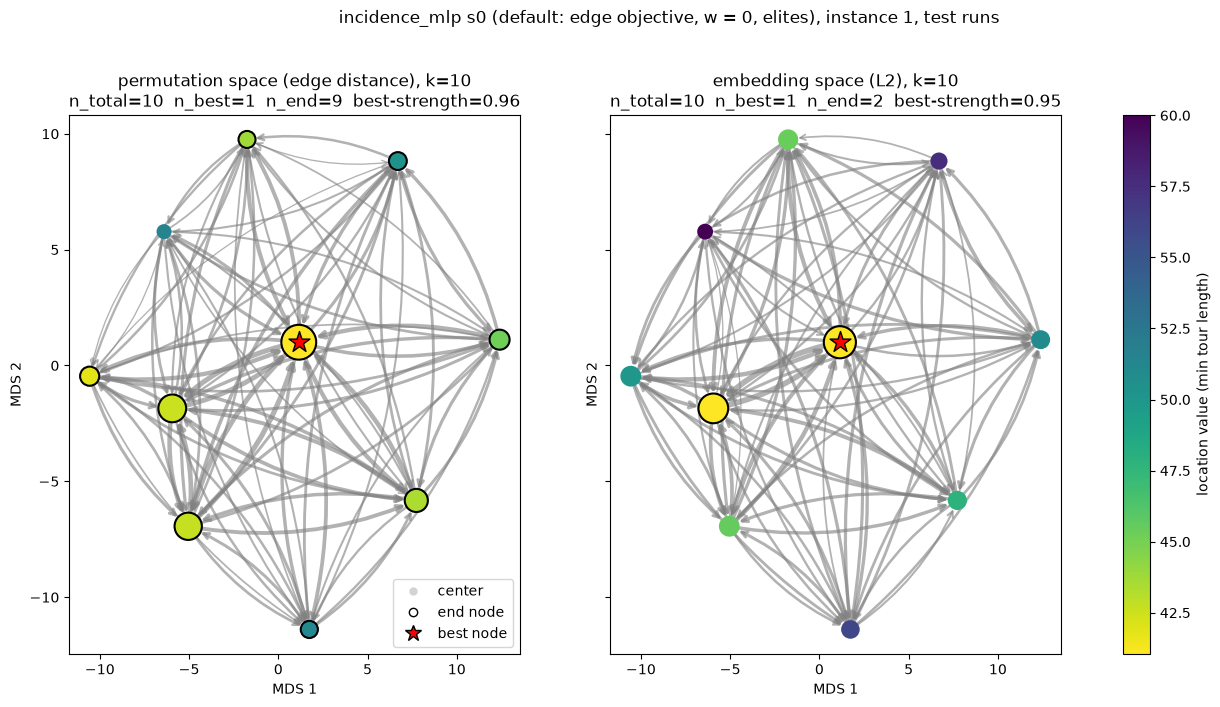

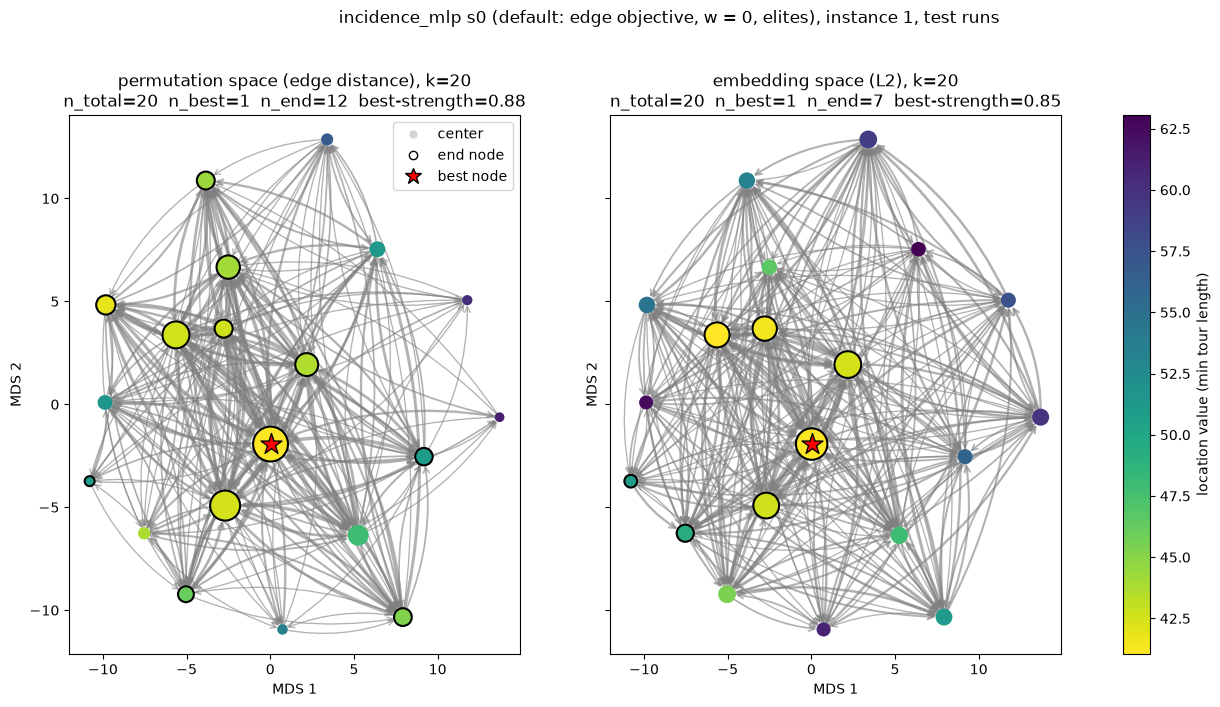

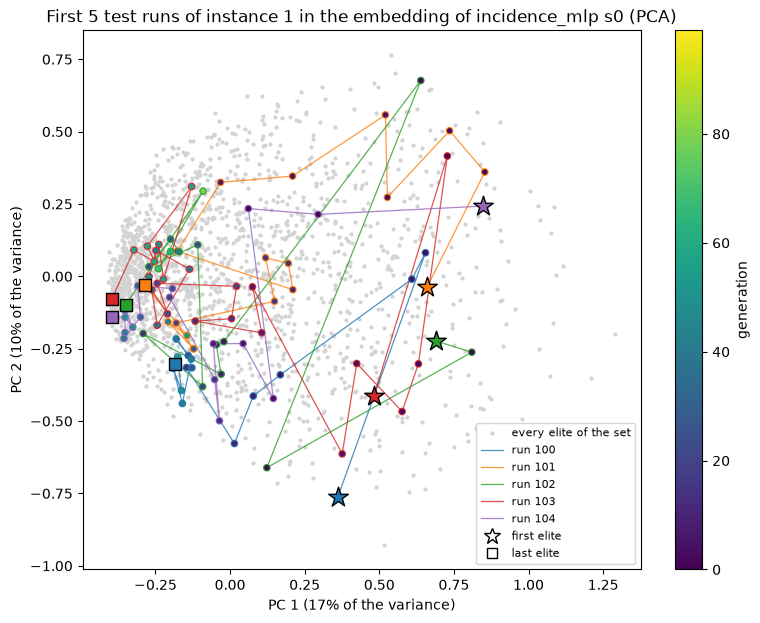

In [12]:
import matplotlib.pyplot as plt

test_data = sets["test"]
Z_default = A.embed(models["incidence_mlp s0"], test_data["perm"], device)
for k in (10, 20):
    fig = P.stn_pair_figure(test_data, Z_default, k, "incidence_mlp s0 (default: edge objective, w = 0, elites), "
                            "instance 1, test runs")
    fig.savefig(P.FINAL_FIGURE_PATH.format(f"stn_incidence_mlp_k{k}"), dpi=150, bbox_inches="tight")
    plt.show()
fig = P.trajectories_pca_figure(test_data, Z_default, np.unique(test_data["run_id"])[:5],
                                "First 5 test runs of instance 1 in the embedding of incidence_mlp s0 (PCA)")
fig.savefig(P.FINAL_FIGURE_PATH.format("trajectories_pca_incidence_mlp"), dpi=150, bbox_inches="tight")
plt.show()

Trajectories of the same 5 test runs in PCA(2) of the edge incidence vectors (baseline (b), no learning) next to PCA(2) of the `incidence_mlp` s0 embedding. In both panels the PCA is fitted on the elites of the training runs (the left panel is exactly baseline (b)); the right panel differs from the figure above only by that fitting set. Saved to `outputs/final_trajectories_pca_incidence_vs_mlp.png`.

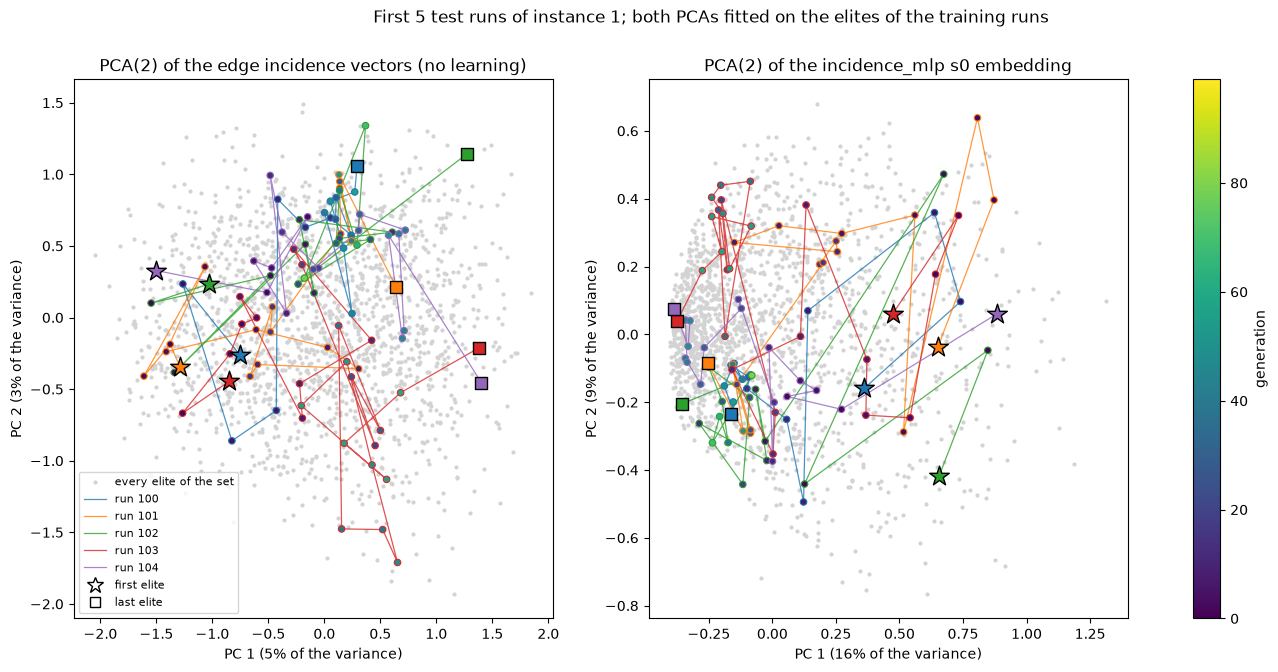

In [13]:
xy_inc, ratio_inc = P.pca_2d(S.edge_matrix(fit_data["perm"]), S.edge_matrix(test_data["perm"]))
xy_mlp, ratio_mlp = P.pca_2d(A.embed(models["incidence_mlp s0"], fit_data["perm"], device), Z_default)
fig = P.trajectories_pair_figure(test_data, [xy_inc, xy_mlp], [ratio_inc, ratio_mlp],
                                 ["PCA(2) of the edge incidence vectors (no learning)",
                                  "PCA(2) of the incidence_mlp s0 embedding"], np.unique(test_data["run_id"])[:5])
fig.suptitle("First 5 test runs of instance 1; both PCAs fitted on the elites of the training runs", y=0.98)
fig.savefig(P.FINAL_FIGURE_PATH.format("trajectories_pca_incidence_vs_mlp"), dpi=150, bbox_inches="tight")
plt.show()

STN of the permutation space, of classical MDS(64) (the reference, no learning) and of the `incidence_mlp` s0 embedding side by side for k = 10 and k = 20 on the test runs of instance 1: the same centers, node positions (metric MDS of the centers' edge distances), color and size scales; n_end and best-strength in every panel title. Saved to `outputs/final_stn_perm_mds_mlp_k10.png` and `outputs/final_stn_perm_mds_mlp_k20.png`.

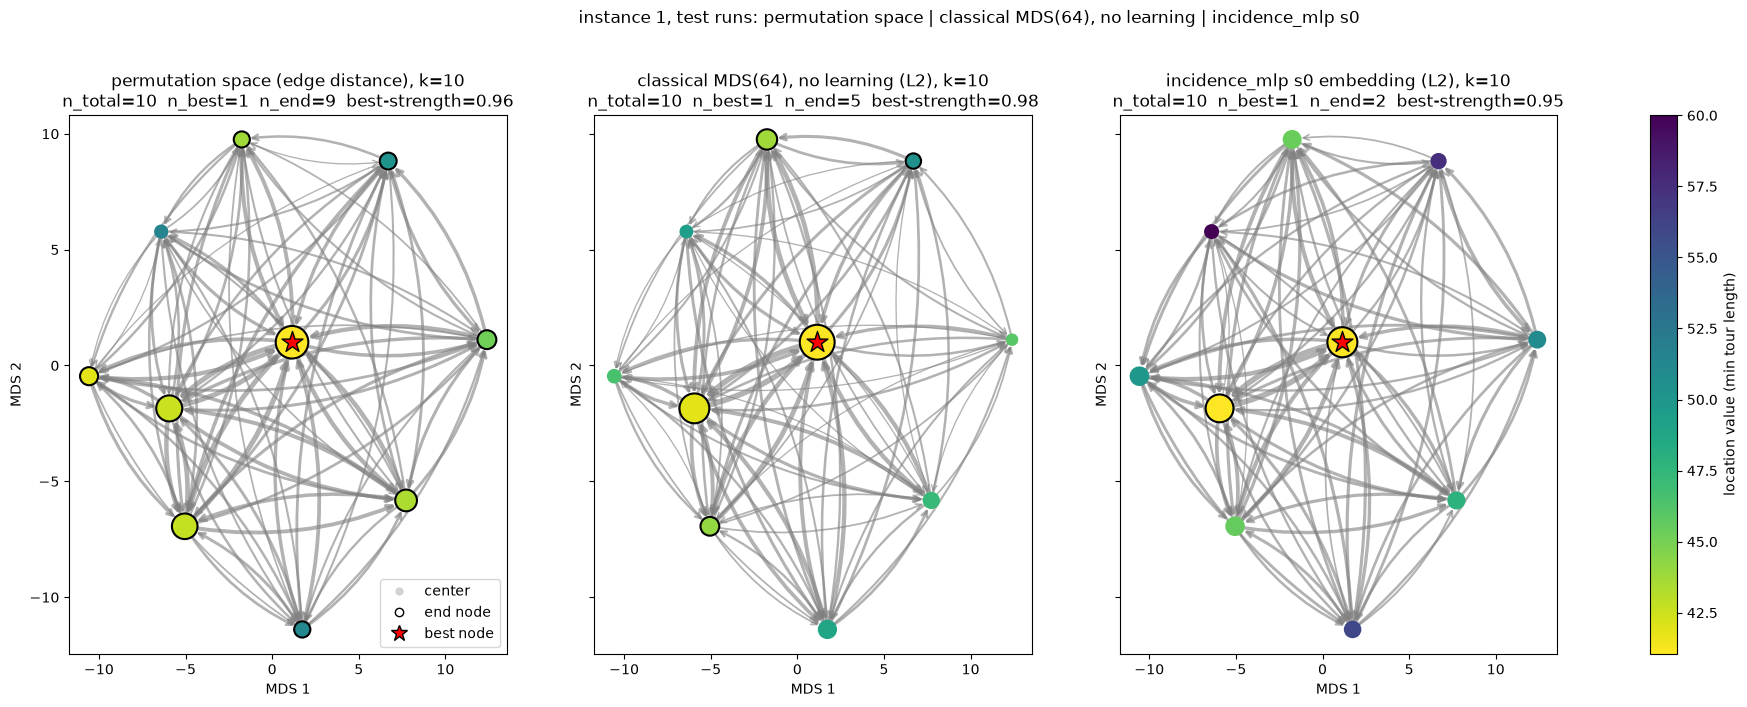

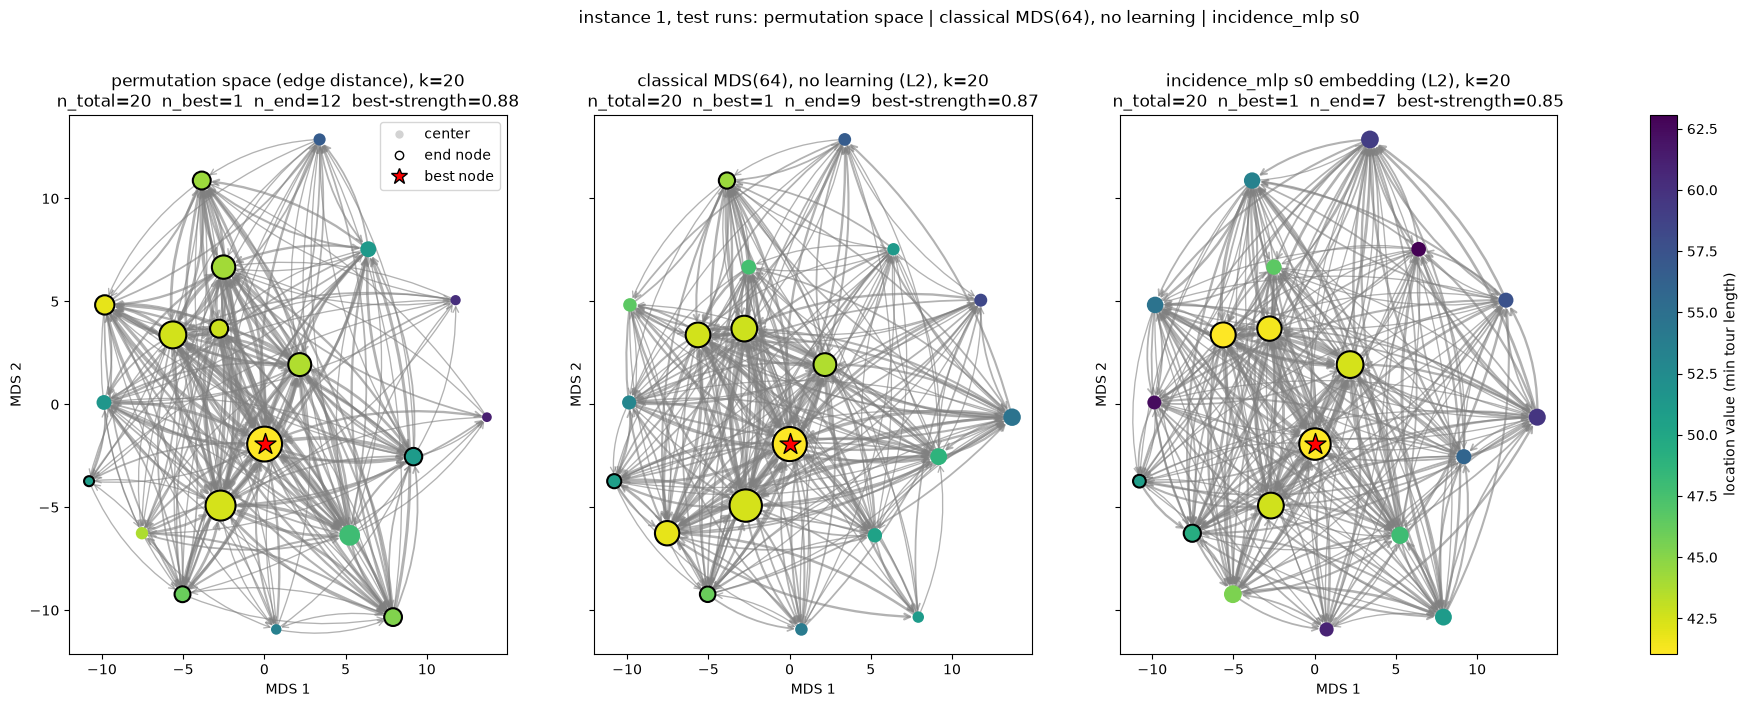

In [14]:
Z_reference = P.baseline_embeddings(test_data["perm"], fit_data["perm"])[0][P.REFERENCE_BASELINE]
for k in (10, 20):
    fig = P.stn_three_panel_figure(test_data, Z_reference, Z_default, k, "instance 1, test runs: permutation space | "
                                   "classical MDS(64), no learning | incidence_mlp s0")
    fig.savefig(P.FINAL_FIGURE_PATH.format(f"stn_perm_mds_mlp_k{k}"), dpi=150, bbox_inches="tight")
    plt.show()

## Conclusions (revised after the baselines)
The checks behind the conclusions: whether `incidence_mlp` beats the reference MDS(64) on any metric of agreement with the permutation space (ARI, soft agreement, Spearman, recall@5, funnel, `end_equal`) on instance 1 and over the replication instances; and the generation probe on the raw 190 incidence features (the basis of the withdrawn claim below), on PCA(2) of them and on `incidence_mlp` s0, on the validation (20 runs), dev and test sets of instance 1.

In [15]:
mlp_above_reference = [f"{r['set']}: {r['metric']}" for r in baseline_diffs if r["baseline"] == P.REFERENCE_BASELINE
                       and r["metric"] in P.AGREEMENT_METRICS and r["vs reference"] == "below"]
print("instance 1, dev and test: agreement metrics where incidence_mlp beats MDS(64):", mlp_above_reference or "none")
rep_reference_diffs = [r for r in rep_base_diff_summary if r["baseline"] == P.REFERENCE_BASELINE]
print("replication, mean over instances: agreement metrics where incidence_mlp beats MDS(64):",
      [r["metric"] for r in rep_reference_diffs if r["metric"] in P.AGREEMENT_METRICS and r["vs reference"] == "below"]
      or "none")
print("replication: instances (of 5) where incidence_mlp is above MDS(64), per metric:",
      {r["metric"]: r["instances below"] for r in rep_reference_diffs})
print()
for set_name in ("validation", "dev", "test"):
    d = sets[set_name]
    X = S.edge_matrix(d["perm"])
    xy, _ = P.pca_2d(S.edge_matrix(fit_data["perm"]), X)
    print(f"{set_name} ({len(np.unique(d['run_id']))} runs, {len(X)} elites): generation probe R^2 (pooled, not clipped): "
          f"190 incidence features {P.generation_r2(d, X):+.3f}, PCA(2) of them {P.generation_r2(d, xy):+.3f}, "
          f"incidence_mlp s0 {P.generation_r2(d, A.embed(models['incidence_mlp s0'], d['perm'], device)):+.3f}")

instance 1, dev and test: agreement metrics where incidence_mlp beats MDS(64): none
replication, mean over instances: agreement metrics where incidence_mlp beats MDS(64): none
replication: instances (of 5) where incidence_mlp is above MDS(64), per metric: {'ARI k>=20': 0, 'soft k>=20': 0, 'spearman': 0, 'recall@5': 0, 'funnel': 3, 'end_equal': 0, 'gen_r2': 2}



validation (20 runs, 392 elites): generation probe R^2 (pooled, not clipped): 190 incidence features -0.095, PCA(2) of them +0.544, incidence_mlp s0 +0.516


dev (100 runs, 1898 elites): generation probe R^2 (pooled, not clipped): 190 incidence features +0.588, PCA(2) of them +0.551, incidence_mlp s0 +0.529


test (100 runs, 1850 elites): generation probe R^2 (pooled, not clipped): 190 incidence features +0.561, PCA(2) of them +0.514, incidence_mlp s0 +0.506


**Conclusions (written after the results).**

1. **Reference.** Classical MDS(64) of the edge distances, a compression without learning fitted on the training elites, is the reference of the project (upper bound without learning) and the anchor row of the project table.
2. **The trained encoder does not beat MDS(64) on any metric of agreement with the permutation space.** On instance 1 (dev and test) and on the mean over the 5 replication instances, `incidence_mlp` is not above MDS(64) on ARI, soft agreement, Spearman, recall@5, the funnel or `end_equal`. Over the replication instances MDS(64) is above on every instance in ARI (+0.275 ± 0.051, mean ± sd of the difference), soft agreement (+0.158 ± 0.028), Spearman (+0.070 ± 0.012), recall@5 (+0.494 ± 0.016) and `end_equal` (+0.249 ± 0.085); the funnel is within noise (+0.003 ± 0.041; `incidence_mlp` above on 3 of 5 instances), as is the generation probe (+0.020 ± 0.025; above on 2 of 5). The STN figures agree: at k = 10 n_end / best-strength are 9 / 0.96 in the permutation space, 5 / 0.98 for MDS(64) and 2 / 0.95 for `incidence_mlp`; at k = 20 12 / 0.88, 9 / 0.87 and 7 / 0.85.
3. **The edge metrics favor MDS by construction.** Every agreement metric is defined by the edge distance (the permutation-space locations and STN, the soft agreement, Spearman, recall@5); classical MDS approximates exactly that distance, while the encoder learns it only through triplets ordered by it. These metrics measure how well a representation reproduces the edge distance, so for them MDS(64) is an upper bound without learning.
4. **Withdrawn: "the encoders encode search progress that the incidence representation does not show".** The claim rested on the generation probe of the 190 raw incidence features on the 20 validation runs of instance 1 (negative R^2: -0.121 in `encoder_architectures.ipynb`, -0.095 with the probe of this notebook), an artifact of a 190-feature ridge probe on 392 elites. On the 100 dev and test runs the same probe gives +0.588 and +0.561, above `incidence_mlp` s0 (+0.529, +0.506), and PCA(2) of the incidence vectors matches `incidence_mlp` on the generation probe (3 seeds, run bootstrap: 0.551 vs 0.542 on dev, 0.514 vs 0.516 on test, within noise on both).
5. **What stands.** The encoder learns part of the edge distance (gains over its own random init on instance 1 and on all 5 replication instances); `incidence_mlp` is above the LSTM in every absolute metric; no encoder transfers between instances.

## Reproducibility
Library versions, seeds, commands and the hashes of the output files are also written to `REPRODUCIBILITY.md`.

In [16]:
for k, v in P.library_versions().items():
    print(f"{k:20s} {v}")

python               3.12.10
platform             Windows-11-10.0.26200-SP0
numpy                2.5.3
scipy                1.18.1
scikit-learn         1.9.1
torch                2.14.0+cu130
networkx             3.6.1
matplotlib           3.11.2
pyyaml               6.0.3
nbformat             5.11.1
nbconvert            7.17.1
cuda (torch build)   13.0
gpu                  NVIDIA GeForce RTX 3050 Laptop GPU
